In [36]:
import pandas as pd

In [37]:
#Importation du dataset users_data.csv de Kaggle
users = pd.read_csv(r"C:\Users\rimla\Stage\users_data.csv")
# Afficher les premières lignes du jeu de données?
users.head()


,id,current_age,retirement_age,birth_year,birth_month,gender,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
0,825,53,66,1966,11,Female,462 Rose Lane,34.15,-117.76,$29278,$59696,$127613,787,5
1,1746,53,68,1966,12,Female,3606 Federal Boulevard,40.76,-73.74,$37891,$77254,$191349,701,5
2,1718,81,67,1938,11,Female,766 Third Drive,34.02,-117.89,$22681,$33483,$196,698,5
3,708,63,63,1957,1,Female,3 Madison Street,40.71,-73.99,$163145,$249925,$202328,722,4
4,1164,43,70,1976,9,Male,9620 Valley Stream Drive,37.76,-122.44,$53797,$109687,$183855,675,1


In [38]:
# Afficher les informations générales sur le jeu de données
users.info()
# Afficher les statistiques descriptives des variables numériques
users.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 2000 non-null   int64  
 1   current_age        2000 non-null   int64  
 2   retirement_age     2000 non-null   int64  
 3   birth_year         2000 non-null   int64  
 4   birth_month        2000 non-null   int64  
 5   gender             2000 non-null   object 
 6   address            2000 non-null   object 
 7   latitude           2000 non-null   float64
 8   longitude          2000 non-null   float64
 9   per_capita_income  2000 non-null   object 
 10  yearly_income      2000 non-null   object 
 11  total_debt         2000 non-null   object 
 12  credit_score       2000 non-null   int64  
 13  num_credit_cards   2000 non-null   int64  
dtypes: float64(2), int64(7), object(5)
memory usage: 218.9+ KB


,id,current_age,retirement_age,birth_year,birth_month,latitude,longitude,credit_score,num_credit_cards
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,999.500000,45.391500,66.237500,1973.803000,6.439000,37.389225,-91.554765,709.734500,3.073000
std,577.494589,18.414092,3.628867,18.421234,3.565338,5.114324,16.283293,67.221949,1.637379
min,0.000000,18.000000,50.000000,1918.000000,1.000000,20.880000,-159.410000,480.000000,1.000000
25%,499.750000,30.000000,65.000000,1961.000000,3.000000,33.837500,-97.395000,681.000000,2.000000
50%,999.500000,44.000000,66.000000,1975.000000,7.000000,38.250000,-86.440000,711.500000,3.000000
75%,1499.250000,58.000000,68.000000,1989.000000,10.000000,41.200000,-80.130000,753.000000,4.000000
max,1999.000000,101.000000,79.000000,2002.000000,12.000000,61.200000,-68.670000,850.000000,9.000000


In [39]:
#Afficher la taille du jeu de données
users.shape

(2000, 14)

In [40]:
#Afficher le type des variable
users.dtypes

id                     int64
current_age            int64
retirement_age         int64
birth_year             int64
birth_month            int64
gender                object
address               object
latitude             float64
longitude            float64
per_capita_income     object
yearly_income         object
total_debt            object
credit_score           int64
num_credit_cards       int64
dtype: object

In [41]:
#Vérifier les valeurs manquantes
users.isnull().sum()

id                   0
current_age          0
retirement_age       0
birth_year           0
birth_month          0
gender               0
address              0
latitude             0
longitude            0
per_capita_income    0
yearly_income        0
total_debt           0
credit_score         0
num_credit_cards     0
dtype: int64

# Aucune valeur n'est manquante

In [42]:
#Verifier les doublons
users.duplicated().sum()

0

# Il n'y a pas de doublons

In [43]:
#Choix des variables pertinentes
X = users[['current_age',
           'per_capita_income',
           'yearly_income',
           'total_debt',
           'credit_score',
           'num_credit_cards']].copy()

# Ces variables décrivent le profil financier des clients :
# - current_age : âge du client
# - per_capita_income : revenu par personne
# - yearly_income : revenu annuel
# - total_debt : dette totale
# - credit_score : score de crédit
# - num_credit_cards : nombre de cartes de crédit
# Elles sont choisies car elles permettent de regrouper les clients selon leurs caractéristiques socio-économiques et leur comportement financier.

In [44]:
#Verification du type des variables choisies
X.dtypes

current_age           int64
per_capita_income    object
yearly_income        object
total_debt           object
credit_score          int64
num_credit_cards      int64
dtype: object

In [45]:
#Transformation des variables de type object en float
X['yearly_income'] = (
    X['yearly_income']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

X['total_debt'] = (
    X['total_debt']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)
X['per_capita_income'] = (
    X['per_capita_income']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [46]:
#Verification du type après transformation
X.dtypes

current_age            int64
per_capita_income    float64
yearly_income        float64
total_debt           float64
credit_score           int64
num_credit_cards       int64
dtype: object

In [47]:
#Vérifier la corrélation entre les variables choisies
X.corr()

,current_age,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
current_age,1.000000,-0.009054,-0.114316,-0.315443,-0.005468,0.484189
per_capita_income,-0.009054,1.000000,0.963975,0.496138,-0.004545,0.018606
yearly_income,-0.114316,0.963975,1.000000,0.550641,0.000167,-0.032877
total_debt,-0.315443,0.496138,0.550641,1.000000,-0.104537,-0.217940
credit_score,-0.005468,-0.004545,0.000167,-0.104537,1.000000,0.237935
num_credit_cards,0.484189,0.018606,-0.032877,-0.217940,0.237935,1.000000


# On remarque que les variables 'yearly_income' et 'per_capita_income' présentent une très forte corrélation (proche de 1). Elles apportent donc une information redondante. Afin de limiter la redondance et d'améliorer l'interprétabilité du modèle, on supprime l'une des deux variables.

In [48]:
#Suppression de la variable per_capita_income
X = X.drop(columns=['per_capita_income'])

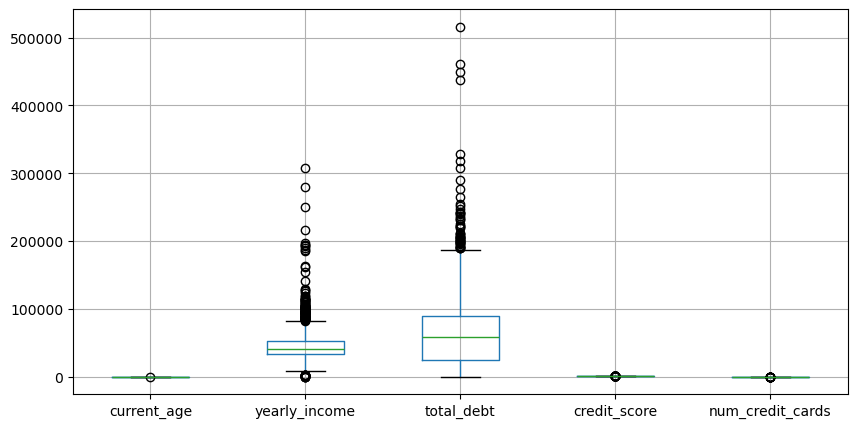

In [49]:
import matplotlib.pyplot as plt

X.boxplot(figsize=(10,5))
plt.show()

# Afficher les boîtes à moustaches des variables numériques afin de visualiser leur distribution et de détecter d'éventuelles valeurs aberrantes

In [50]:
# Normalisation des variables numériques afin qu'elles soient sur la même échelle
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Calcul de la moyenne et de l'écart-type sur les données, puis transformation des variables afin qu'elles soient centrées (moyenne = 0) et réduites (écart-type = 1)
X_scaled = scaler.fit_transform(X)

In [51]:
# Convertir les données normalisées en DataFrame afin de conserver les noms des colonnes
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [52]:
# Vérifier les statistiques descriptives après la normalisation
X_scaled.describe()

,current_age,yearly_income,total_debt,credit_score,num_credit_cards
count,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03
mean,-2.842171e-17,1.065814e-16,-5.684342e-17,-3.765876e-16,1.154632e-17
std,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00
min,-1.487901e+00,-1.988739e+00,-1.219525e+00,-3.418407e+00,-1.266364e+00
25%,-8.360635e-01,-5.610761e-01,-7.603731e-01,-4.275640e-01,-6.554793e-01
50%,-7.558603e-02,-2.162705e-01,-1.044898e-01,2.627031e-02,-4.459458e-02
75%,6.848914e-01,3.037655e-01,4.854543e-01,6.437826e-01,5.662901e-01
max,3.020644e+00,1.136745e+01,8.662735e+00,2.087125e+00,3.620714e+00


# On remarque que la moyenne (mean) est très proche de 0 et que l'écart-type (std) est proche de 1, ce qui confirme que les données ont été correctement standardisées.

In [ ]:
import numpy as np

# Appliquer une transformation logarithmique pour éliminer les outliers
X_log = X.copy()

X_log["yearly_income"] = np.log1p(X_log["yearly_income"])
X_log["total_debt"] = np.log1p(X_log["total_debt"])

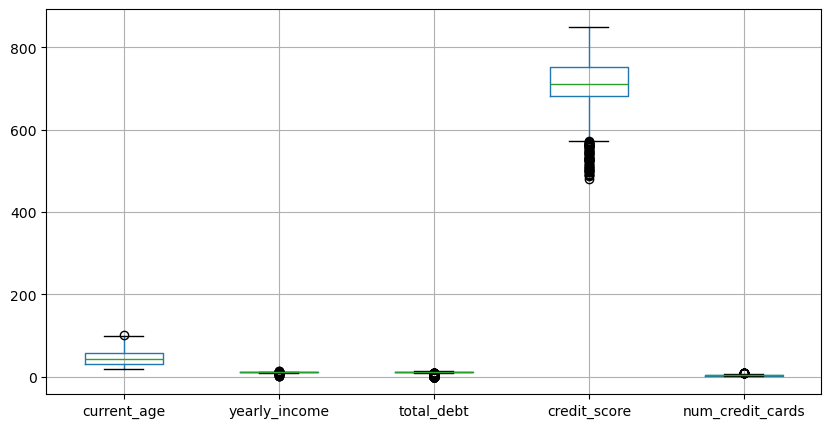

In [ ]:
#Vérification du boxplot après transformation
import matplotlib.pyplot as plt

X_log.boxplot(figsize=(10,5))
plt.show()

In [55]:
# Asymétrie avant transformation
X[['yearly_income', 'total_debt']].skew()

yearly_income    3.447004
total_debt       1.811097
dtype: float64

In [56]:
# Asymétrie après transformation
X_log[['yearly_income', 'total_debt']].skew()

yearly_income   -7.244227
total_debt      -2.894450
dtype: float64

In [57]:
# Vérifier les valeurs minimales et maximales
X_log[['yearly_income', 'total_debt']].describe()

,yearly_income,total_debt
count,2000.000000,2000.000000
mean,10.612551,10.116314
std,0.638493,2.653035
min,0.693147,0.000000
25%,10.398778,10.085298
50%,10.615101,10.972534
75%,10.872361,11.397195
max,12.634665,13.154374


In [ ]:
# Afficher les clients dont le revenu annuel est inférieur à 1000 afin de vérifier s'il s'agit de valeurs aberrantes ou d'observations plausibles.
users.loc[X["yearly_income"] < 1000]

,id,current_age,retirement_age,birth_year,birth_month,gender,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
662,1016,41,53,1978,8,Female,165 Fourth Street,32.95,-117.19,$0,$553,$740,719,3
751,1151,53,65,1966,12,Male,353 South Boulevard,40.35,-74.65,$0,$920,$1914,788,3
764,1942,77,63,1942,3,Female,2073 South Avenue,40.71,-73.99,$0,$1,$0,673,3
1342,1364,47,72,1972,11,Male,37845 Main Street,32.93,-97.22,$0,$3,$5,750,2
1426,1998,65,67,1954,9,Male,10 Third Avenue,37.56,-122.37,$0,$645,$790,688,3
1543,1202,63,65,1956,10,Female,881 Ocean View Street,41.83,-87.68,$0,$4,$0,691,3
1686,1348,83,64,1936,6,Male,873 Summit Street,40.64,-73.94,$0,$2,$0,667,6
1731,1649,64,63,1956,2,Male,8146 Third Avenue,29.79,-95.82,$0,$399,$323,729,3


In [ ]:
# Examiner les principales caractéristiques des clients dont le revenu annuel est inférieur à 1000 afin d'évaluer si ces observations sont plausibles ou s'il s'agit de valeurs potentiellement aberrantes.
users.loc[X["yearly_income"] < 1000,
          ["current_age",
           "yearly_income",
           "total_debt",
           "credit_score",
           "num_credit_cards"]]

,current_age,yearly_income,total_debt,credit_score,num_credit_cards
662,41,$553,$740,719,3
751,53,$920,$1914,788,3
764,77,$1,$0,673,3
1342,47,$3,$5,750,2
1426,65,$645,$790,688,3
1543,63,$4,$0,691,3
1686,83,$2,$0,667,6
1731,64,$399,$323,729,3


# Une transformation logarithmique a été testée afin de réduire l'effet des valeurs extrêmes. Cependant, elle a conduit à une forte asymétrie négative de certaines variables. Les observations correspondant à de très faibles revenus qui ne peuvent pas être considérées comme des erreurs, les données originales ont été conservées et seules les variables ont été standardisées avant l'application de K-Means.